# Loan Risk Analysis

## Project objective

The aim of this project is to use past loan records to understand which loans were marked Good or Bad. I will explore the data and compare two simple machine learning models.

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Keep the Excel workbook in the same folder as this notebook.
file = "AssessmentDataScientist.xlsx"

application_df = pd.read_excel(file, sheet_name="Application Data")
loan_df = pd.read_excel(file, sheet_name="Loan Performance")

print("Application data:", application_df.shape)
print("Loan performance data:", loan_df.shape)

display(application_df.head())
display(loan_df.head())

c:\Users\ishug\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Application data: (647, 31)
Loan performance data: (1285, 2)


c:\Users\ishug\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636


,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


The workbook has two sheets: one contains application details, and the other contains loan outcomes.

## 2. EDA and data checks

Missing values: 308
Duplicate rows: 0

Application status


status
Approved    647
Name: count, dtype: int64


Loan outcomes


flgGood
Good    769
Bad     516
Name: count, dtype: int64

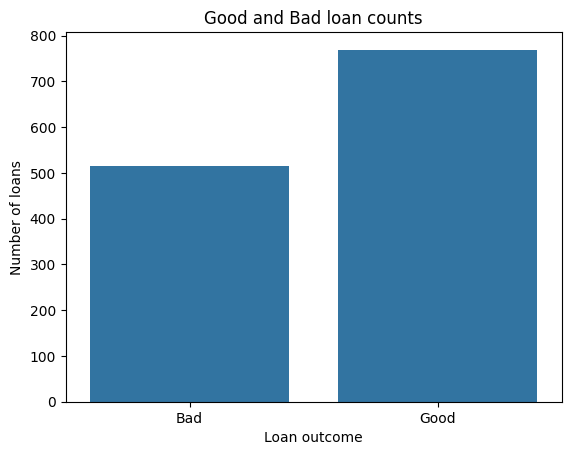

,amount_requested,monthly_income_amount
count,647.000000,647.000000
mean,597.604328,2617.151468
std,168.855126,1706.526011
min,250.000000,300.000000
25%,500.000000,1502.000000
50%,500.000000,2289.000000
75%,800.000000,3200.000000
max,800.000000,19392.000000


In [2]:
print("Missing values:", application_df.isna().sum().sum())
print("Duplicate rows:", application_df.duplicated().sum())

print("\nApplication status")
display(application_df["status"].value_counts())

print("\nLoan outcomes")
display(loan_df["flgGood"].value_counts())

sns.countplot(data=loan_df, x="flgGood")
plt.title("Good and Bad loan counts")
plt.xlabel("Loan outcome")
plt.ylabel("Number of loans")
plt.show()

display(application_df[["amount_requested", "monthly_income_amount"]].describe())

These checks show the basic data quality and the number of Good and Bad loan outcomes. The charts help me understand the data before modelling.

## 3. Join the data

In [3]:
application_df["key"] = application_df["customer_id"].astype(str).str.lower().str.strip()
loan_df["key"] = loan_df["idLoan"].astype(str).str.split("-").str[0].str.lower().str.strip()

combined = pd.merge(loan_df, application_df, on="key", how="left", indicator=True)

print("Matched records:", (combined["_merge"] == "both").sum())
print("Unmatched records:", (combined["_merge"] == "left_only").sum())

matched = combined[combined["_merge"] == "both"].copy()

display(matched["flgGood"].value_counts())

Matched records: 656
Unmatched records: 629


flgGood
Bad     354
Good    302
Name: count, dtype: int64

I join the sheets using the customer ID. Some loan records do not match an application record, so I keep track of them as a limitation.

## 4. Prepare the data

In [4]:
customer_result = matched.groupby("key")["flgGood"].apply(
    lambda x: 1 if "Bad" in x.values else 0
)

data = application_df.merge(
    customer_result.rename("target"),
    on="key",
    how="inner"
)

data["birth_date"] = pd.to_datetime(data["birth_date"], errors="coerce")
data["application_when"] = pd.to_datetime(data["application_when"], errors="coerce")
data["age"] = (data["application_when"] - data["birth_date"]).dt.days / 365

drop_columns = [
    "customer_id", "key", "email", "bank_routing_number",
    "address_zip", "birth_date", "application_when",
    "status", "amount_approved", "duration_approved",
    "payment_amount_approved"
]

X = data.drop(columns=drop_columns + ["target"], errors="ignore")
y = data["target"]

X = X.fillna(X.median(numeric_only=True))
X = pd.get_dummies(X, drop_first=True)
X = X.fillna(0)

print("Rows for modelling:", len(X))
print("Number of features:", X.shape[1])
print("Bad loan percentage:", round(y.mean() * 100, 1), "%")

Rows for modelling: 640
Number of features: 43
Bad loan percentage: 55.3 %


The target is what the model predicts: 0 means Good and 1 means Bad. I remove customer identifiers and approved-loan terms that may not be available for a new application.

## 5. Split the data and prepare features

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 480
Testing rows: 160


I use most of the records for training and keep some for testing. Missing values and text categories are handled before the models learn from the data.

## 6. Train Logistic Regression

c:\Users\ishug\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.55
ROC-AUC: 0.625
              precision    recall  f1-score   support

        Good       0.50      0.57      0.53        72
         Bad       0.60      0.53      0.57        88

    accuracy                           0.55       160
   macro avg       0.55      0.55      0.55       160
weighted avg       0.56      0.55      0.55       160



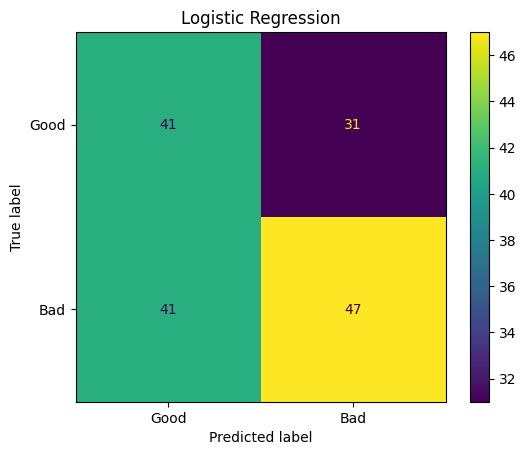

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt

log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train, y_train)

log_pred = log_model.predict(X_test)
log_prob = log_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, log_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, log_prob), 3))
print(classification_report(y_test, log_pred, target_names=["Good", "Bad"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, log_pred, display_labels=["Good", "Bad"]
)
plt.title("Logistic Regression")
plt.show()

Logistic Regression is the first model. I use its test results as a baseline to compare with Random Forest.

## 7. Train Random Forest

Accuracy: 0.656
ROC-AUC: 0.664
              precision    recall  f1-score   support

        Good       0.63      0.57      0.60        72
         Bad       0.67      0.73      0.70        88

    accuracy                           0.66       160
   macro avg       0.65      0.65      0.65       160
weighted avg       0.65      0.66      0.65       160



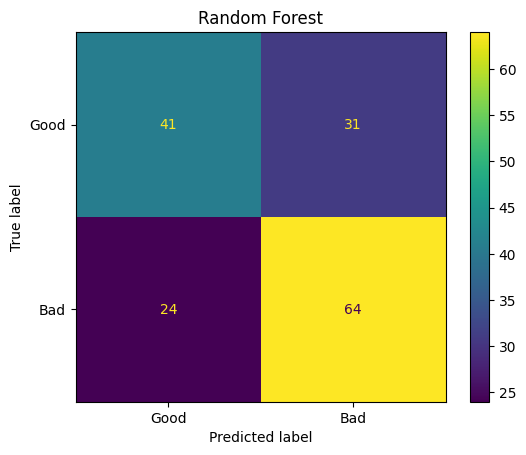

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt

forest_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced"
)
forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)
forest_prob = forest_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, forest_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, forest_prob), 3))
print(classification_report(y_test, forest_pred, target_names=["Good", "Bad"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, forest_pred, display_labels=["Good", "Bad"]
)
plt.title("Random Forest")
plt.show()

Random Forest combines multiple decision trees. I train it on the same data split so the comparison with Logistic Regression is fair.

## 8. Compare the models

In [8]:
from sklearn.metrics import accuracy_score, roc_auc_score
import pandas as pd

# Refresh predictions using the current test set to avoid stale notebook variables.
# X_test and y_test should come from the same train_test_split cell.
if hasattr(y_test, "loc") and hasattr(X_test, "index"):
    y_test = y_test.loc[X_test.index]

log_pred = log_model.predict(X_test)
log_prob = log_model.predict_proba(X_test)[:, 1]

forest_pred = forest_model.predict(X_test)
forest_prob = forest_model.predict_proba(X_test)[:, 1]

# Catch mismatched variables early with a clear message.
assert len(y_test) == len(log_pred) == len(forest_pred), (
    f"Test/prediction size mismatch: y_test={len(y_test)}, "
    f"log_pred={len(log_pred)}, forest_pred={len(forest_pred)}. "
    "Restart the kernel and run all cells from the beginning."
)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, forest_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, forest_prob)
    ]
})

display(comparison.round(3))

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.550,0.625
1,Random Forest,0.656,0.664


I compare both models using the same test records. I also look at recall for Bad loans because missed risky loans may be costly.

## Conclusion

This is a first-level analysis, not a production lending system. The application sheet contains approved applicants only, some loan records do not match, and the customer-level target labels a customer Bad if any matched loan is Bad. These limits should be considered before using the results.

Before making lending decisions, I would confirm the target definition, investigate unmatched records, and test the model on newer data.